# SC4001 : Programmng Assignment

#### Part B: Classification Problem

In [1]:
import torch
print(torch.__version__)

2.5.1+cu121


In [9]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam
from captum.attr import visualization as viz
import os

# Ensure reproducibility
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## Data Pipeline Initialization

In [10]:
def load_and_preprocess_data(filepath='chestxray_binary_64.npz', batch_size=128):
    data = np.load(filepath)
    print("Keys inside the npz file:", data.files)

    
    # Extract splits using the correct keys from your npz file
    X_train, y_train = data['train_images'], data['train_labels']
    X_val, y_val = data['val_images'], data['val_labels']
    X_test, y_test = data['test_images'], data['test_labels']
    
    # Scale to [0, 1]
    X_train, X_val, X_test = X_train / 255.0, X_val / 255.0, X_test / 255.0
    
    # Normalize using train mean and std
    train_mean = np.mean(X_train)
    train_std = np.std(X_train)
    
    X_train = (X_train - train_mean) / train_std
    X_val = (X_val - train_mean) / train_std
    X_test = (X_test - train_mean) / train_std
    
    # Convert to PyTorch tensors (N, C, H, W)
    X_train_t = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
    y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
    X_val_t = torch.tensor(X_val, dtype=torch.float32).unsqueeze(1)
    y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
    X_test_t = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)
    y_test_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)
    
    # Create DataLoaders
    train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size, shuffle=False)
    
    return train_loader, val_loader, test_loader, X_test_t, y_test_t

# Run the function
train_loader, val_loader, test_loader, X_test_t, y_test_t = load_and_preprocess_data()
print("Data loaded successfully! Shapes:", X_test_t.shape)

Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Data loaded successfully! Shapes: torch.Size([624, 1, 64, 64])


## Training Config

In [11]:
class EarlyStopping:
    def __init__(self, patience=4, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

def train_model(model, train_loader, val_loader, lr, max_epochs=20, weight_decay=0.0):
    criterion = nn.BCEWithLogitsLoss()
    # Added weight_decay option here
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    early_stopping = EarlyStopping()
    
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(max_epochs):
        model.train()
        train_loss = 0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * inputs.size(0)
            
        model.eval()
        val_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
                
                # Squeezing preds to match targets if needed
                preds = (torch.sigmoid(outputs) > 0.5).float()
                correct += (preds == targets).sum().item()
                total += targets.size(0)
                
        # Store normalized losses and accuracy
        epoch_train_loss = train_loss / len(train_loader.dataset)
        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = correct / total
        
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        
        early_stopping(epoch_val_loss)
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break
            
    return history

## Convolution Base

In [12]:
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c, kernel_size, stride=1):
        super().__init__()
        # PyTorch calculates SAME padding for odd kernels as kernel_size // 2
        padding = kernel_size // 2 if stride == 1 else (kernel_size // 2)
        self.conv = nn.Conv2d(in_c, out_c, kernel_size, stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_c)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))

# Plotting Function

In [13]:
def plot_sweep_results(results, label_prefix='Param', save_filename='sweep_comparison.png'):
    os.makedirs('images', exist_ok=True)
    # 1x3 grid to include Training Loss alongside Validation metrics
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for key, history in results.items():
        axes[0].plot(history['train_loss'], label=f'{label_prefix}: {key}', linewidth=2)
        axes[1].plot(history['val_loss'], label=f'{label_prefix}: {key}', linewidth=2)
        axes[2].plot(history['val_acc'], label=f'{label_prefix}: {key}', linewidth=2)

    # Train Loss Plot
    axes[0].set_title('Training Loss')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.7)

    # Val Loss Plot
    axes[1].set_title('Validation Loss')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.7)

    # Val Accuracy Plot
    axes[2].set_title('Validation Accuracy')
    axes[2].set_xlabel('Epochs')
    axes[2].set_ylabel('Accuracy')
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    output_path = os.path.join('images', save_filename)
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"Plot saved to {output_path}")
    plt.show()

## Alex-Net Like

In [14]:
class B1_AlexNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1, 16, 5),
            nn.MaxPool2d(2, 2),
            ConvBlock(16, 32, 5),
            nn.MaxPool2d(2, 2),
            ConvBlock(32, 64, 3),
            nn.MaxPool2d(2, 2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64, bias=True),
            nn.Dropout(0.5),
            nn.ReLU(),
            nn.Linear(64, 32, bias=True),
            nn.Dropout(0.5),
            nn.ReLU(),
            nn.Linear(32, 1, bias=True)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

## B1 Hyperparameter Search

Training B1 with LR: 1e-05
Training B1 with LR: 0.0001
Training B1 with LR: 0.001
Early stopping triggered at epoch 17
Training B1 with LR: 0.01
Early stopping triggered at epoch 20
Training B1 with LR: 0.1
Early stopping triggered at epoch 16
Plot saved to images/learning_rate_comparison.png


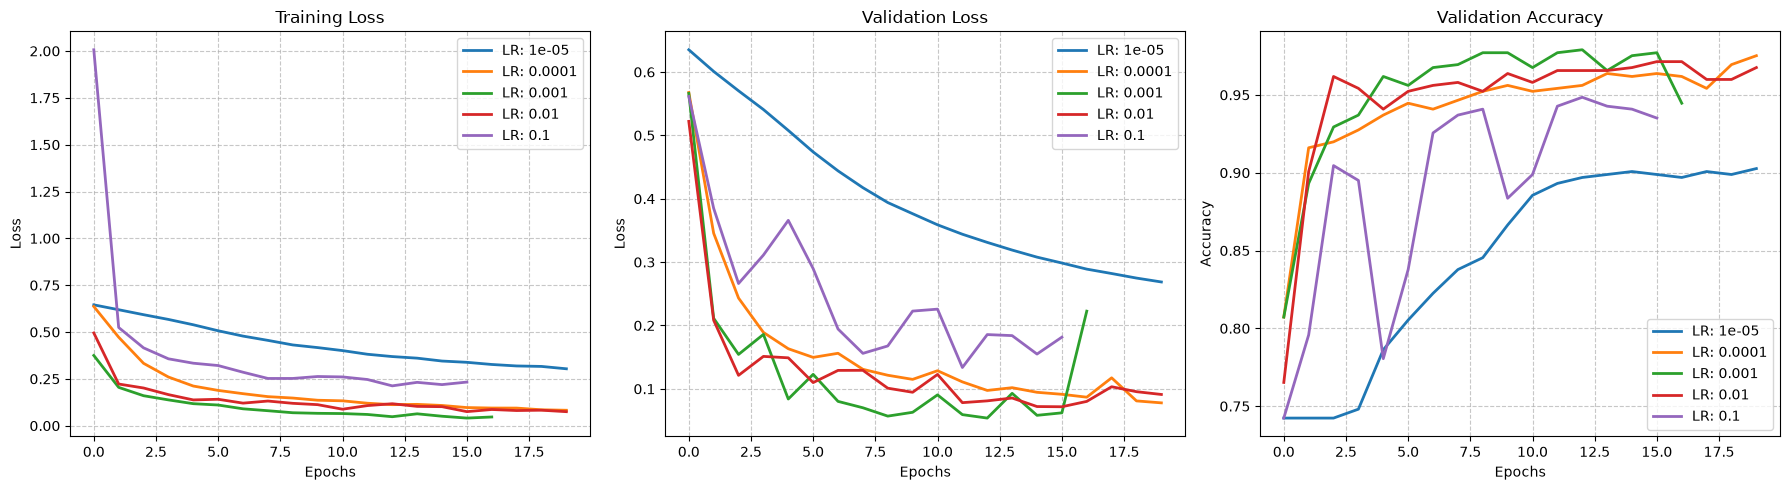

Best LR for B1: 0.001


In [15]:
def run_lr_sweep(lrs, train_loader, val_loader, device):
    results = {}
    for lr in lrs:
        print(f"Training B1 with LR: {lr}")
        model_b1 = B1_AlexNet().to(device)
        
        # Make sure your train_model function returns a dictionary 
        # containing 'train_loss', 'val_loss', and 'val_acc' lists
        history = train_model(model_b1, train_loader, val_loader, lr)
        results[lr] = history
        
    return results

# 3. Execution Pipeline
lrs = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

# Run the sweep
b1_results = run_lr_sweep(lrs, train_loader, val_loader, device)

# Plot the 3-panel results
plot_sweep_results(
    results=b1_results, 
    label_prefix='LR', 
    save_filename='learning_rate_comparison.png'
)

# Extract best LR
best_lr_b1 = max(b1_results, key=lambda k: max(b1_results[k]['val_acc']))
print(f"Best LR for B1: {best_lr_b1}")

# BCG Like Architecture

In [16]:
class B2_VGG(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1, 8, 3),
            ConvBlock(8, 8, 3),
            nn.MaxPool2d(2, 2),
            ConvBlock(8, 16, 3),
            ConvBlock(16, 16, 3),
            nn.MaxPool2d(2, 2),
            ConvBlock(16, 32, 3),
            ConvBlock(32, 32, 3),
            nn.MaxPool2d(2, 2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32, 1, bias=True)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

# B2 Hyperparameter Search

#### Early Stopping

In [17]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# 1. Early Stopping (Required by assignment specifications)
class EarlyStopping:
    def __init__(self, patience=4, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

##### Training Function

In [21]:
def train_vgg_model(model, train_loader, val_loader, lr, device, epochs=20):
    criterion = nn.BCEWithLogitsLoss()
    
    # # Weight decay and gradient clipping kept for VGG stability
    optimizer = optim.Adam(model.parameters(), lr=lr ) #weight_decay=1e-4)
    # scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
    early_stopping = EarlyStopping(patience=4, min_delta=1e-4)
    
    # Now tracking train_loss alongside val metrics
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(epochs):
        # --- Training Phase ---
        model.train()
        running_train_loss = 0.0
        
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_train_loss += loss.item() * inputs.size(0)
            
        # --- Validation Phase ---
        model.eval()
        running_val_loss = 0.0
        correct = 0
        total = 0
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                running_val_loss += loss.item() * inputs.size(0)
                
                preds = (torch.sigmoid(outputs) > 0.5).float()
                correct += (preds == targets).sum().item()
                total += targets.size(0)
                
        # --- Metrics Calculation ---
        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_acc = correct / total
        
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        
        # scheduler.step(epoch_val_loss)
        early_stopping(epoch_val_loss)
        
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break
            
    return history

In [22]:
def run_batch_size_sweep(batch_sizes, lr, device):
    results = {}
    for bs in batch_sizes:
        print(f"Training VGG with Batch Size: {bs} at LR: {lr}")
        train_loader_bs, val_loader_bs, _, _, _ = load_and_preprocess_data(batch_size=bs)
        
        model_b2 = B2_VGG().to(device)
        history = train_vgg_model(model_b2, train_loader_bs, val_loader_bs, lr, device)
        results[bs] = history
        
    return results

# 4. Modular Plotting Function (3 Panels)
def plot_sweep_results(results, save_filename='vgg_batch_size_comparison.png'):
    os.makedirs('images', exist_ok=True)
    # Expanded to a 1x3 grid to include Training Loss
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for bs, history in results.items():
        axes[0].plot(history['train_loss'], label=f'Batch: {bs}', linewidth=2)
        axes[1].plot(history['val_loss'], label=f'Batch: {bs}', linewidth=2)
        axes[2].plot(history['val_acc'], label=f'Batch: {bs}', linewidth=2)

    # Train Loss Plot
    axes[0].set_title('Training Loss')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.7)

    # Val Loss Plot
    axes[1].set_title('Validation Loss')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.7)

    # Val Accuracy Plot
    axes[2].set_title('Validation Accuracy')
    axes[2].set_xlabel('Epochs')
    axes[2].set_ylabel('Accuracy')
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    output_path = os.path.join('images', save_filename)
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"Plot saved to {output_path}")
    plt.show()

Training VGG with Batch Size: 16 at LR: 0.001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 15
Training VGG with Batch Size: 32 at LR: 0.001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 15
Training VGG with Batch Size: 64 at LR: 0.001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 12
Training VGG with Batch Size: 128 at LR: 0.001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 12
Training VGG with Batch Size: 256 at LR: 0.001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 1

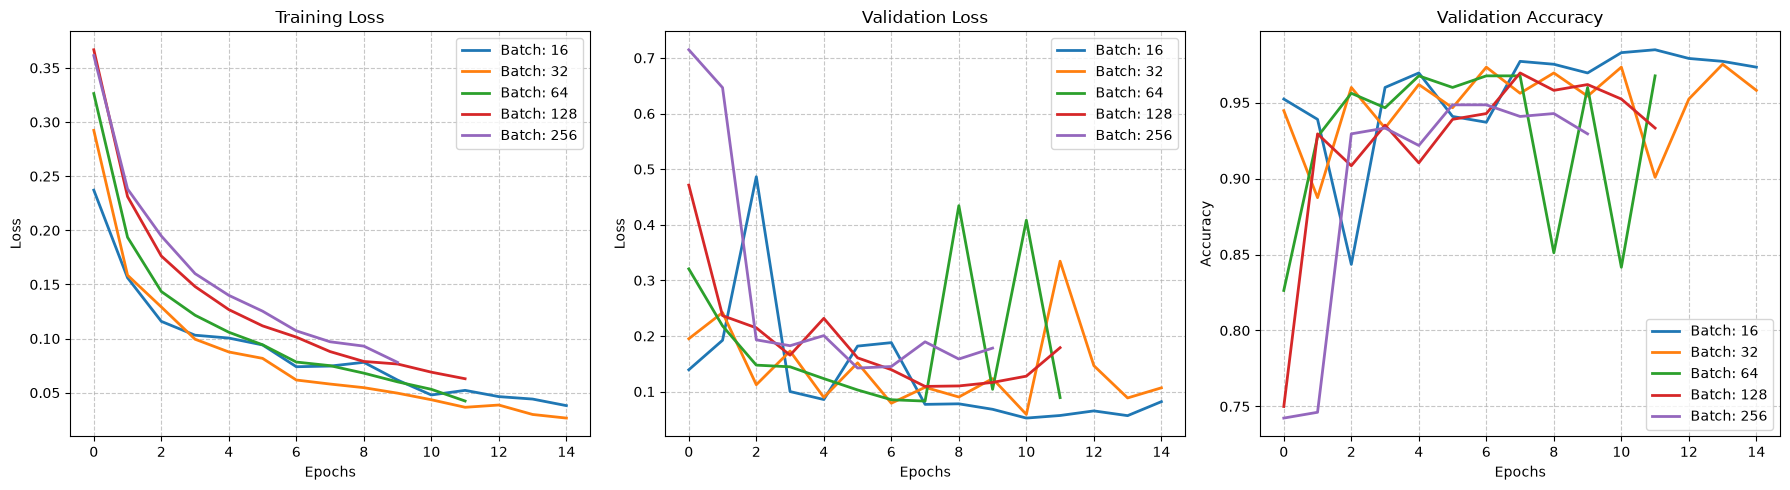

Best Batch Size for VGG: 16


In [23]:
# 5. Execution Pipeline
batch_sizes = [16, 32, 64, 128, 256]

# Note: The assignment specifies using the optimal learning rate found in B1 for this step.
# Make sure `best_lr_b1` is defined from your previous B1 code cell.
current_lr = best_lr_b1 if 'best_lr_b1' in locals() else 1e-4 

b2_results = run_batch_size_sweep(batch_sizes, current_lr, device)
plot_sweep_results(b2_results)

best_bs_b2 = max(b2_results, key=lambda k: max(b2_results[k]['val_acc']))
print(f"Best Batch Size for VGG: {best_bs_b2}")

# B3 - ResNet Like Architecture

In [24]:
class ResBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = ConvBlock(in_c, out_c, 3, stride=stride)
        # Note: BatchNorm and ReLU are inside ConvBlock
        self.conv2 = nn.Conv2d(out_c, out_c, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        
        self.shortcut = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_c)
            )
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.conv1(x)
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out) # ReLU applied after residual addition

class B3_ResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.prep = nn.Sequential(
            ConvBlock(1, 16, 3),
            nn.MaxPool2d(2, 2)
        )
        self.layer1 = ResBlock(16, 16, stride=1)
        self.layer2 = ResBlock(16, 32, stride=2)
        self.layer3 = ResBlock(32, 64, stride=2)
        
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(64, 1, bias=True)

    def forward(self, x):
        x = self.prep(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

--- Training B3 ResNet ---
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 11
Plot saved to images/resnet_b3_history.png


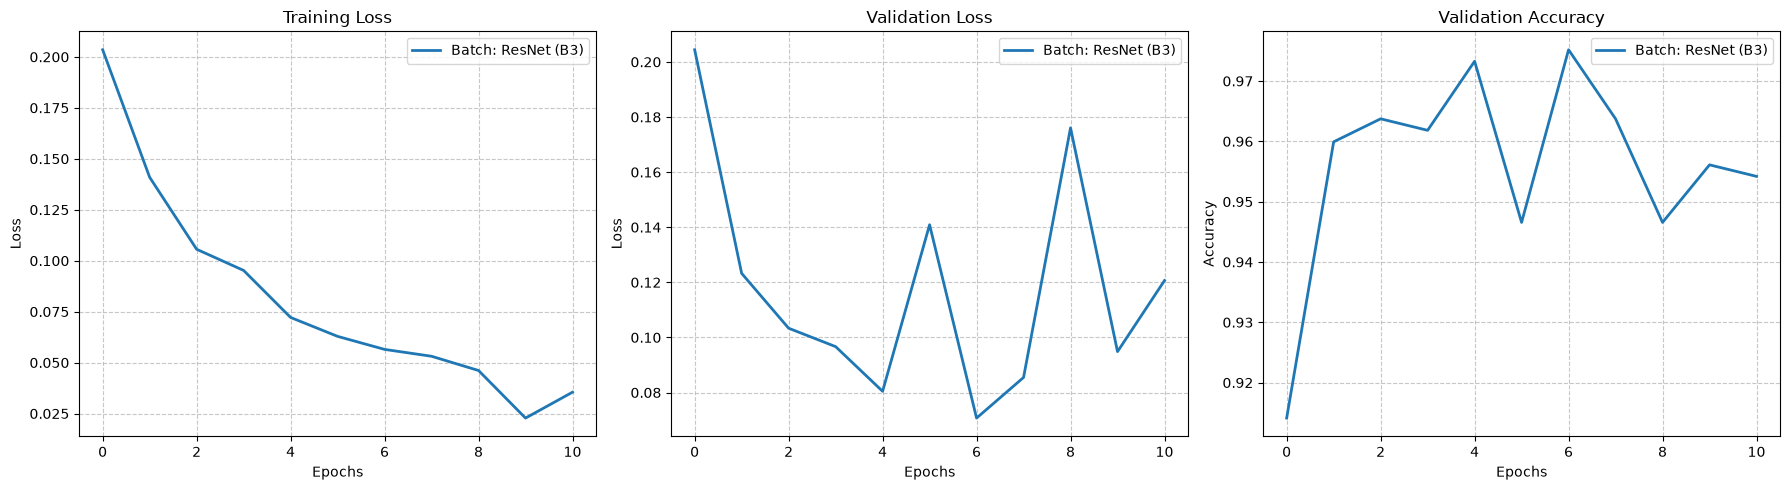


--- Final Test Set Evaluation & Metrics ---

Model: B1_AlexNet
  Accuracy    : 0.6250
  Precision   : 0.6250
  Sensitivity : 1.0000
  Specificity : 0.0000

--- Architecture Summary for B1_AlexNet ---

Model: B2_VGG
  Accuracy    : 0.6250
  Precision   : 0.6250
  Sensitivity : 1.0000
  Specificity : 0.0000

--- Architecture Summary for B2_VGG ---

Model: B3_ResNet
  Accuracy    : 0.9087
  Precision   : 0.8881
  Sensitivity : 0.9769
  Specificity : 0.7949

--- Architecture Summary for B3_ResNet ---


In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from torchinfo import summary

model_b1 = B1_AlexNet().to(device)
model_b2 = B2_VGG().to(device)

# --- 1. Modular Evaluation Function (Not defined in earlier cells) ---
def evaluate_model(model, loader, device):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = torch.round(torch.sigmoid(outputs))
            
            y_true.extend(targets.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    sensitivity = recall_score(y_true, y_pred, zero_division=0)
    
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    else:
        specificity = 0.0
        
    return {
        'accuracy': acc,
        'precision': precision,
        'sensitivity': sensitivity,
        'specificity': specificity
    }

# --- 2. Execution Pipeline for B3 ResNet ---
print("--- Training B3 ResNet ---")

# Reuse load_and_preprocess_data with the optimal batch size (best_bs_b2)
train_loader_final, val_loader_final, test_loader_final, _, _ = load_and_preprocess_data(batch_size=best_bs_b2)

model_b3 = B3_ResNet().to(device)

# Reuse the train_model function defined in Cell 3 (tracks train loss, val loss, val acc, & EarlyStopping)
b3_history = train_model(
    model=model_b3, 
    train_loader=train_loader_final, 
    val_loader=val_loader_final, 
    lr=best_lr_b1, 
    max_epochs=20
)

# Reuse the 3-panel plotting function (plot_sweep_results) by passing a single-item dictionary
plot_sweep_results(
    results={'ResNet (B3)': b3_history}, 
    # label_prefix='Model', 
    save_filename='resnet_b3_history.png'
)

# --- 3. Final Comparison & Architecture Summaries ---
models = {
    'B1_AlexNet': model_b1,
    'B2_VGG': model_b2,
    'B3_ResNet': model_b3
}

print("\n--- Final Test Set Evaluation & Metrics ---")
for name, model in models.items():
    metrics = evaluate_model(model, test_loader_final, device)
    print(f"\nModel: {name}")
    print(f"  Accuracy    : {metrics['accuracy']:.4f}")
    print(f"  Precision   : {metrics['precision']:.4f}")
    print(f"  Sensitivity : {metrics['sensitivity']:.4f}")
    print(f"  Specificity : {metrics['specificity']:.4f}")
    
    print(f"\n--- Architecture Summary for {name} ---")
    summary(model, input_size=(best_bs_b2, 1, 64, 64), col_names=["input_size", "output_size", "num_params", "mult_adds"])

# Consolidated Model Metrics

In [36]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

def evaluate_detailed_metrics(model, loader, device):
    """Computes loss, accuracy, classification error, sensitivity, and specificity."""
    model.eval()
    y_true, y_pred = [], []
    criterion = nn.BCEWithLogitsLoss()
    val_loss = 0.0
    
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)
            
            preds = (torch.sigmoid(outputs) > 0.5).float()
            y_true.extend(targets.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    loss_val = val_loss / len(loader.dataset)
    acc = accuracy_score(y_true, y_pred)
    class_error = 1.0 - acc
    sensitivity = recall_score(y_true, y_pred, zero_division=0)
    
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    else:
        specificity = 0.0
        
    return {
        'val_loss': loss_val,
        'accuracy': acc,
        'classification_error': class_error,
        'sensitivity': sensitivity,
        'specificity': specificity
    }

def train_model_comprehensive(model, train_loader, val_loader, lr, device, max_epochs=20, weight_decay=0.0):
    """Trains the model and records comprehensive validation metrics per epoch."""
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    early_stopping = EarlyStopping(patience=4, min_delta=1e-4)
    
    history = {
        'train_loss': [], 
        'val_loss': [], 
        'val_acc': [], 
        'val_class_error': [],
        'val_sensitivity': [], 
        'val_specificity': []
    }
    
    for epoch in range(max_epochs):
        model.train()
        train_loss = 0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)
            
        epoch_train_loss = train_loss / len(train_loader.dataset)
        val_metrics = evaluate_detailed_metrics(model, val_loader, device)
        
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(val_metrics['val_loss'])
        history['val_acc'].append(val_metrics['accuracy'])
        history['val_class_error'].append(val_metrics['classification_error'])
        history['val_sensitivity'].append(val_metrics['sensitivity'])
        history['val_specificity'].append(val_metrics['specificity'])
        
        early_stopping(val_metrics['val_loss'])
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break
            
    return history

In [37]:
def plot_separate_validation_figures(results, label_prefix='Param', name_suffix='sweep'):
    """Generates two separate figures for Validation Loss and Validation Accuracy."""
    os.makedirs('images', exist_ok=True)
    
    # Figure 1: Validation Loss
    plt.figure(figsize=(8, 5))
    for key, history in results.items():
        plt.plot(history['val_loss'], label=f'{label_prefix}: {key}', linewidth=2)
    plt.title(f'Validation Loss ({label_prefix} Sweep)')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(f'images/{name_suffix}_val_loss.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Figure 2: Validation Accuracy
    plt.figure(figsize=(8, 5))
    for key, history in results.items():
        plt.plot(history['val_acc'], label=f'{label_prefix}: {key}', linewidth=2)
    plt.title(f'Validation Accuracy ({label_prefix} Sweep)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(f'images/{name_suffix}_val_acc.png', dpi=300, bbox_inches='tight')
    plt.show()

In [38]:
def generate_sweep_metrics_table(results, param_name='Learning Rate'):
    """Creates the required summary table from sweep results at the best epoch."""
    table_data = []
    for param, history in results.items():
        best_epoch_idx = np.argmin(history['val_loss']) # Optimal based on lowest val loss
        table_data.append({
            param_name: param,
            'Best Epoch': best_epoch_idx + 1,
            'Val Loss': f"{history['val_loss'][best_epoch_idx]:.4f}",
            'Val Class Error': f"{history['val_class_error'][best_epoch_idx]:.4f}",
            'Sensitivity': f"{history['val_sensitivity'][best_epoch_idx]:.4f}",
            'Specificity': f"{history['val_specificity'][best_epoch_idx]:.4f}"
        })
    return pd.DataFrame(table_data)

In [39]:
from torchinfo import summary

def create_architecture_comparison_table(models, test_loader, device, batch_size):
    """Builds the final comparison table for B1, B2, and B3 architectures."""
    comparison_data = []
    
    for name, model in models.items():
        metrics = evaluate_detailed_metrics(model, test_loader, device)
        
        # Get model summary stats using torchinfo
        model_summary = summary(model, input_size=(batch_size, 1, 64, 64), verbose=0)
        total_params = model_summary.total_params
        total_mult_adds = model_summary.total_mult_adds
        
        comparison_data.append({
            'Architecture': name,
            'Accuracy': f"{metrics['accuracy']:.4f}",
            'Classification Error': f"{metrics['classification_error']:.4f}",
            'Sensitivity': f"{metrics['sensitivity']:.4f}",
            'Specificity': f"{metrics['specificity']:.4f}",
            'Learnable Parameters': f"{total_params:,}",
            'Mult-Adds (FLOPs)': f"{total_mult_adds:,}"
        })
        
    return pd.DataFrame(comparison_data)

# Generate and display the final comparison table
models_dict = {
    'B1_AlexNet': model_b1,
    'B2_VGG': model_b2,
    'B3_ResNet': model_b3
}

final_comparison_df = create_architecture_comparison_table(models_dict, test_loader_final, device, best_bs_b2)
print("--- Final Architecture Comparison Table (B1 - B3) ---")
display(final_comparison_df)

--- Final Architecture Comparison Table (B1 - B3) ---


,Architecture,Accuracy,Classification Error,Sensitivity,Specificity,Learnable Parameters,Mult-Adds (FLOPs)
0,B1_AlexNet,0.6250,0.3750,1.0000,0.0000,"99,569","312,514,064"
1,B2_VGG,0.6250,0.3750,1.0000,0.0000,"18,185","155,717,648"
2,B3_ResNet,0.9087,0.0913,0.9769,0.7949,"77,169","202,386,960"


# Explainable AI

In [28]:
print("--- AlexNet (model_b1) Layers ---")
for idx, layer in enumerate(model_b1.features):
    print(f"{idx}: {type(layer)}")

print("\n--- VGG (model_b2) Layers ---")
for idx, layer in enumerate(model_b2.features):
    print(f"{idx}: {type(layer)}")

--- AlexNet (model_b1) Layers ---
0: <class '__main__.ConvBlock'>
1: <class 'torch.nn.modules.pooling.MaxPool2d'>
2: <class '__main__.ConvBlock'>
3: <class 'torch.nn.modules.pooling.MaxPool2d'>
4: <class '__main__.ConvBlock'>
5: <class 'torch.nn.modules.pooling.MaxPool2d'>
6: <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>

--- VGG (model_b2) Layers ---
0: <class '__main__.ConvBlock'>
1: <class '__main__.ConvBlock'>
2: <class 'torch.nn.modules.pooling.MaxPool2d'>
3: <class '__main__.ConvBlock'>
4: <class '__main__.ConvBlock'>
5: <class 'torch.nn.modules.pooling.MaxPool2d'>
6: <class '__main__.ConvBlock'>
7: <class '__main__.ConvBlock'>
8: <class 'torch.nn.modules.pooling.MaxPool2d'>
9: <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>


--- Generating Smooth Grad-CAM Visualizations ---


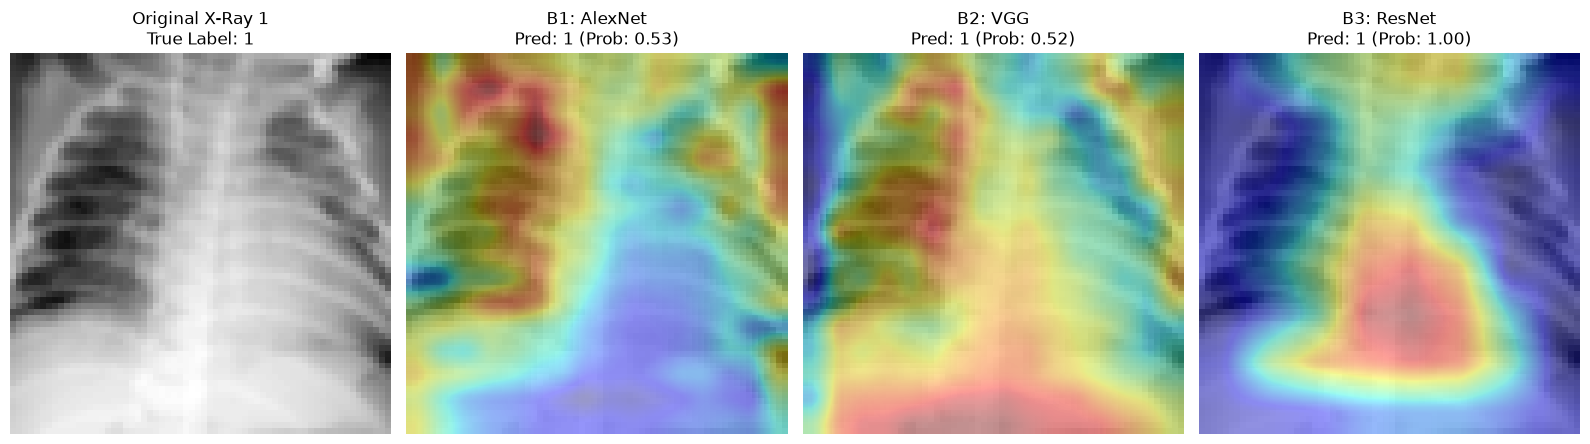

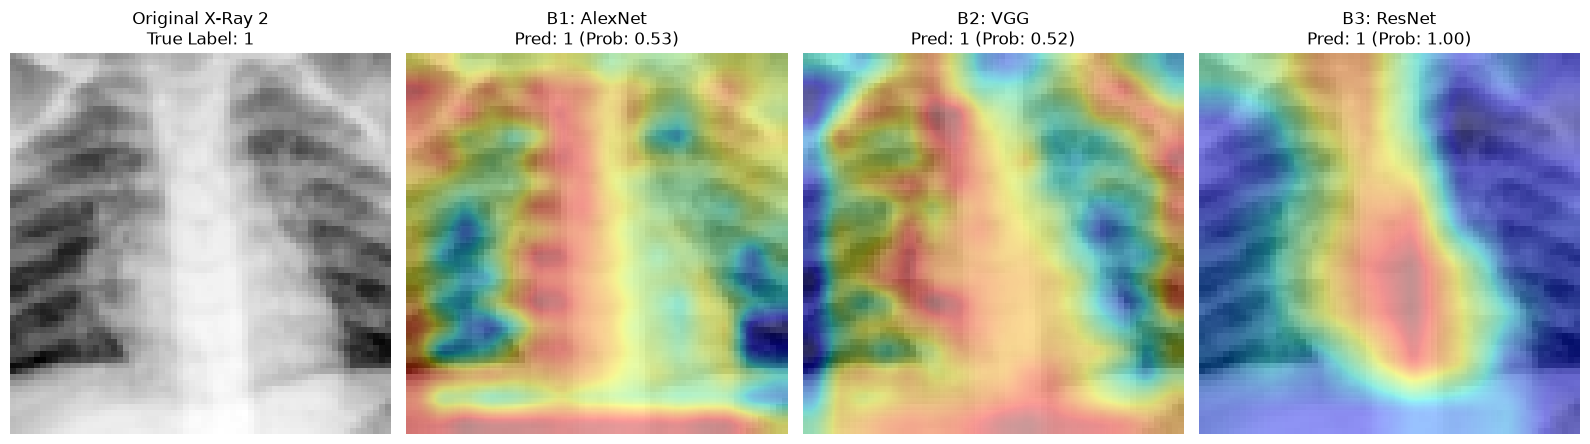

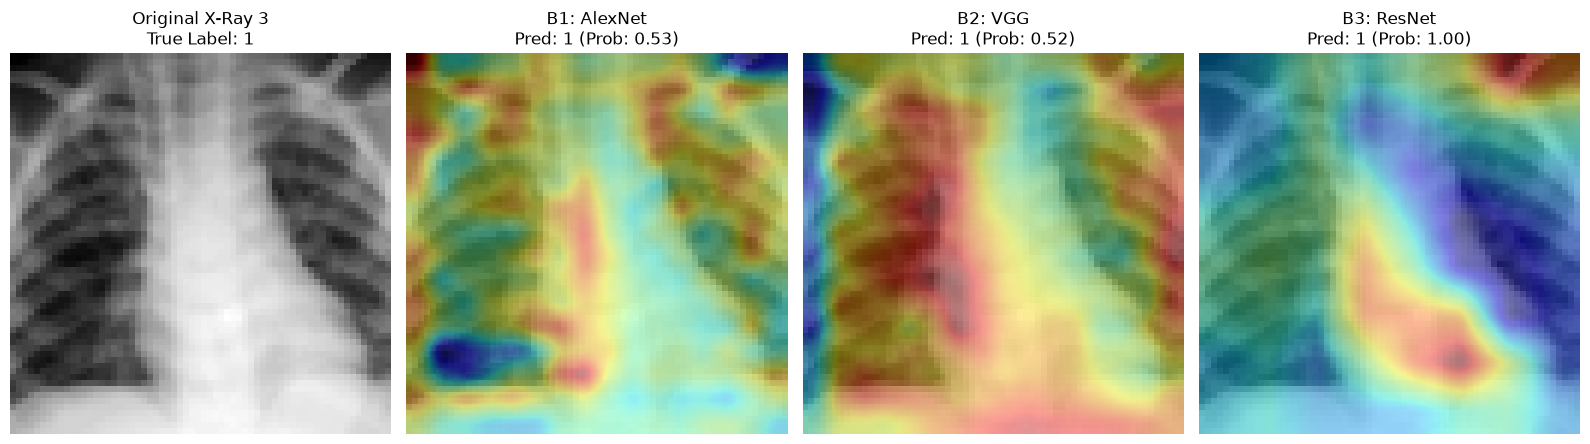

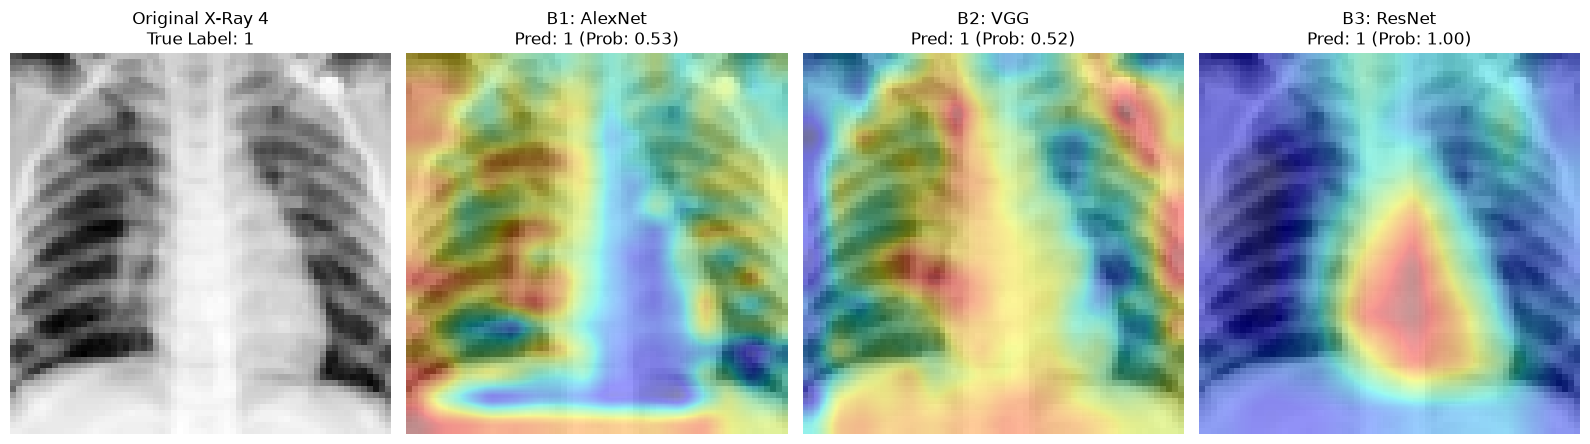

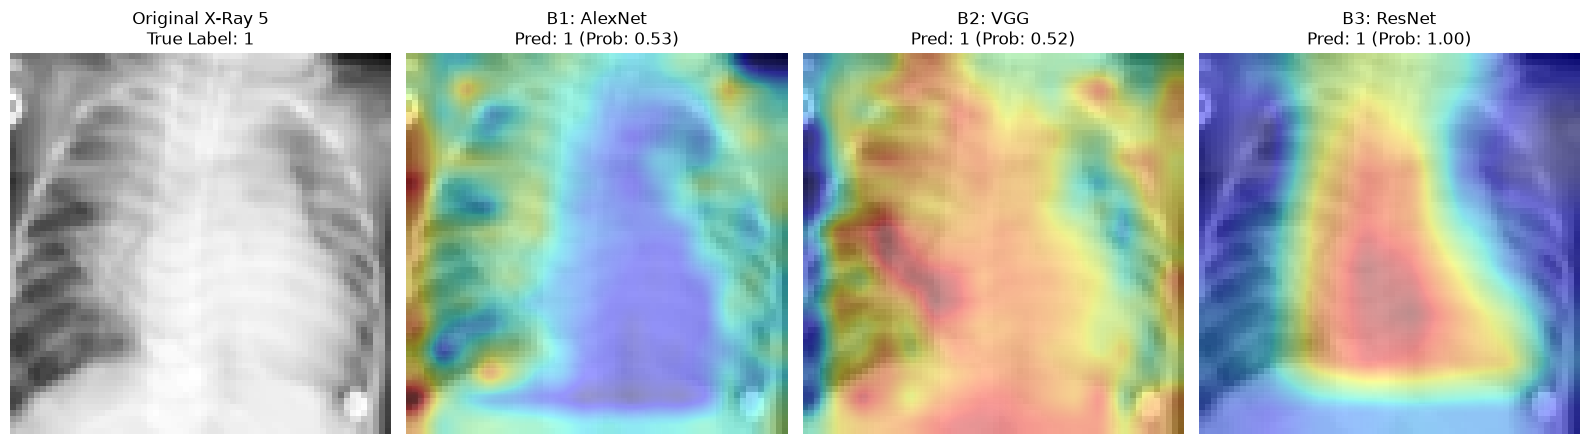

Smooth Grad-CAM images successfully generated and saved to 'images/gradcam/'!
ROC Curve plot saved successfully to images/roc_curve_comparison.png


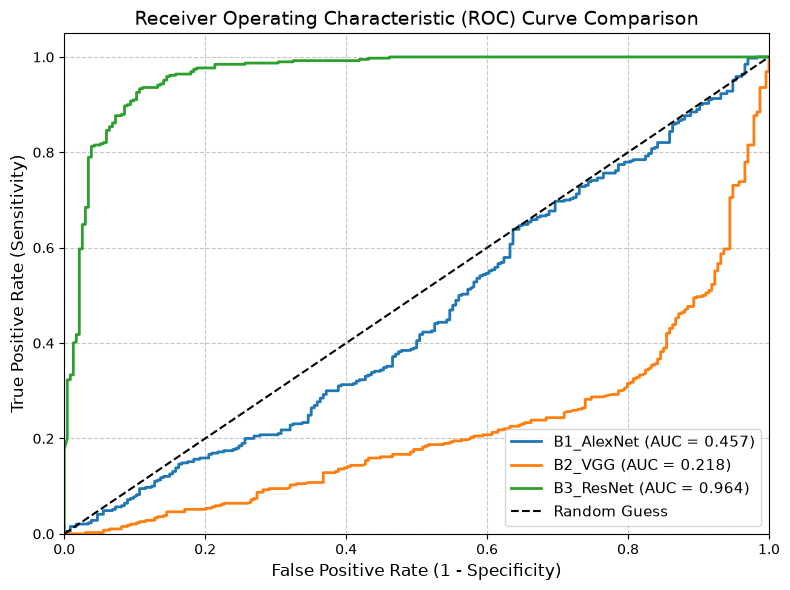

In [40]:
import os
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from captum.attr import LayerGradCam

# --- 1. Helper Function to Find Conv Layers ---
def get_conv_from_block(block):
    """Searches for any Conv2d module inside a custom block."""
    for m in block.modules():
        if isinstance(m, torch.nn.Conv2d):
            return m
    raise ValueError("No Conv2d found in this block")

# --- 2. Modular Grad-CAM Visualization Function ---
def generate_and_save_gradcam(models, sample_images, sample_labels, device, save_dir='images/gradcam'):
    """Generates, overlays, and saves smooth Grad-CAM heatmaps with True/Pred labels."""
    os.makedirs(save_dir, exist_ok=True)
    
    # Initialize LayerGradCam using appropriate target layers for B1, B2, and B3
    cam_b1 = LayerGradCam(models['B1_AlexNet'], get_conv_from_block(models['B1_AlexNet'].features[4]))
    cam_b2 = LayerGradCam(models['B2_VGG'], get_conv_from_block(models['B2_VGG'].features[6]))
    cam_b3 = LayerGradCam(models['B3_ResNet'], models['B3_ResNet'].layer3)

    cams = [cam_b1, cam_b2, cam_b3]
    model_names = ['B1: AlexNet', 'B2: VGG', 'B3: ResNet']
    model_keys = list(models.keys())

    print("--- Generating Smooth Grad-CAM Visualizations ---")
    for i in range(len(sample_images)):
        img = sample_images[i:i+1].to(device) # Shape: (1, 1, H, W)
        true_label = int(sample_labels[i].item()) # Get the true ground truth label
        
        orig_img_np = img.squeeze(0).cpu().permute(1, 2, 0).numpy().squeeze()
        
        fig, axes = plt.subplots(1, 4, figsize=(16, 5))
        
        # Plot Original X-Ray
        axes[0].imshow(orig_img_np, cmap='gray')
        axes[0].set_title(f"Original X-Ray {i+1}\nTrue Label: {true_label}")
        axes[0].axis('off')
        
        # Generate and overlay Grad-CAM for each model
        for idx, (cam, name, key) in enumerate(zip(cams, model_names, model_keys), start=1):
            model = models[key]
            
            # 1. Get model prediction
            model.eval()
            with torch.no_grad():
                output = model(img)
                prob = torch.sigmoid(output).item()
                pred = 1 if prob > 0.5 else 0
                
            # 2. Generate Attribution map
            attr = cam.attribute(img, target=None)
            attr_up = F.interpolate(attr, size=img.shape[2:], mode='bilinear', align_corners=False)
            
            hm = attr_up.squeeze().detach().cpu().numpy()
            if hm.max() > hm.min():
                hm = (hm - hm.min()) / (hm.max() - hm.min()) # Normalize between 0 and 1
                
            # 3. Plot
            axes[idx].imshow(orig_img_np, cmap='gray')
            axes[idx].imshow(hm, cmap='jet', alpha=0.4, interpolation='bilinear')
            axes[idx].set_title(f"{name}\nPred: {pred} (Prob: {prob:.2f})")
            axes[idx].axis('off')
            
        plt.tight_layout()
        save_path = os.path.join(save_dir, f'sample_{i+1}_gradcam.png')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()

    print(f"Smooth Grad-CAM images successfully generated and saved to '{save_dir}/'!")

# --- 3. Modular ROC Curve Evaluation & Plotting Function ---
def evaluate_and_plot_roc(models, test_loader, device, save_filename='roc_curve_comparison.png'):
    """Computes probabilities, AUC, and plots ROC curves for multiple models."""
    os.makedirs('images', exist_ok=True)
    plt.figure(figsize=(8, 6))
    
    for name, model in models.items():
        model.eval()
        y_true, y_probs = [], []
        with torch.no_grad():
            for inputs, targets in test_loader:
                inputs = inputs.to(device)
                outputs = model(inputs)
                probs = torch.sigmoid(outputs)
                y_true.extend(targets.cpu().numpy())
                y_probs.extend(probs.cpu().numpy())
                
        y_true = np.array(y_true)
        y_probs = np.array(y_probs)
        
        fpr, tpr, _ = roc_curve(y_true, y_probs)
        roc_auc = auc(fpr, tpr)
        
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})', linewidth=2)

    plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Guess')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
    plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
    plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=14)
    plt.legend(loc="lower right", fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    roc_output_path = os.path.join('images', save_filename)
    plt.savefig(roc_output_path, dpi=300, bbox_inches='tight')
    print(f"ROC Curve plot saved successfully to {roc_output_path}")
    plt.show()

# --- 4. Execution Pipeline ---
# Package models dictionary for easy iteration
models_dict = {
    'B1_AlexNet': model_b1,
    'B2_VGG': model_b2,
    'B3_ResNet': model_b3
}

# Select 5 random pneumonia positive samples (target == 1)
pneumonia_indices = torch.where(y_test_t == 1)[0]
sample_indices = pneumonia_indices[torch.randperm(len(pneumonia_indices))[:5]]

# Grab BOTH the images and their true labels
sample_images = X_test_t[sample_indices]
sample_labels = y_test_t[sample_indices]

# Run Grad-CAM Generation & Overlay (now passing sample_labels)
generate_and_save_gradcam(models_dict, sample_images, sample_labels, device)

# Run ROC Curve Analysis & Plotting
evaluate_and_plot_roc(models_dict, test_loader_final, device)

--- Generating Smooth Grad-CAM Visualizations ---


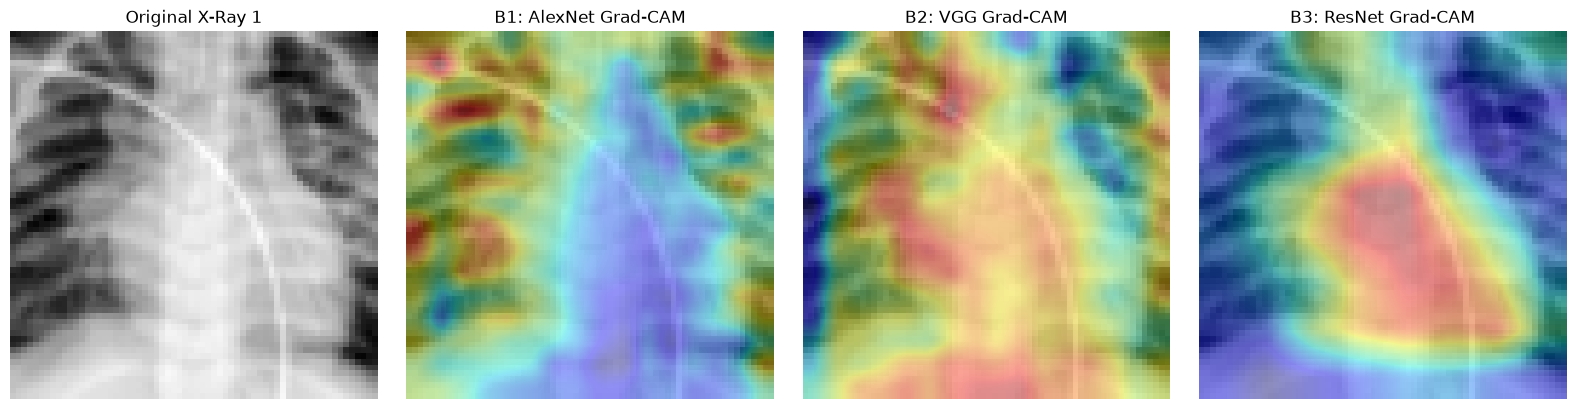

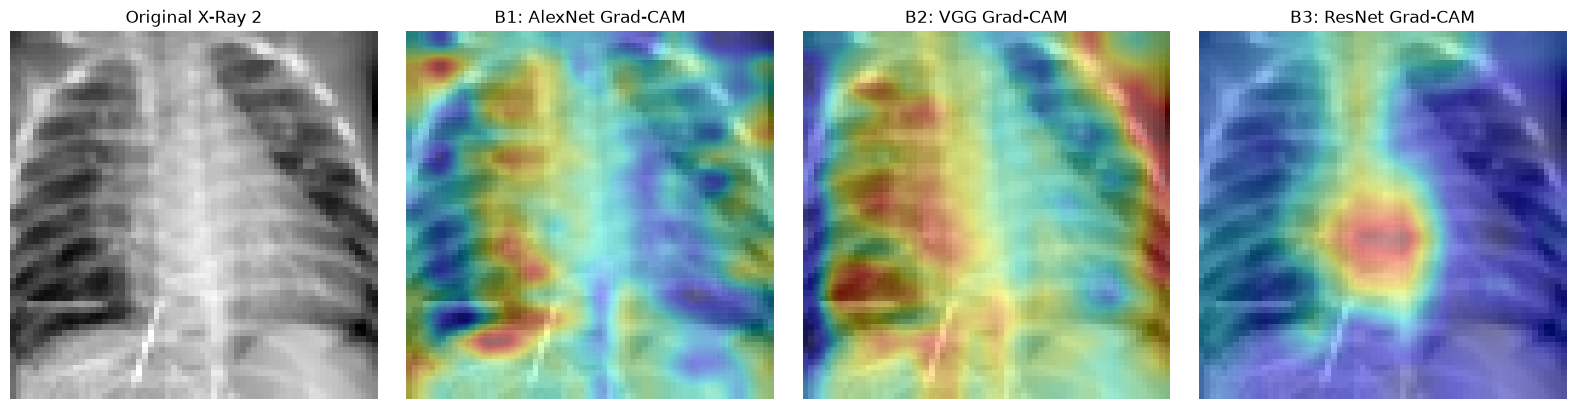

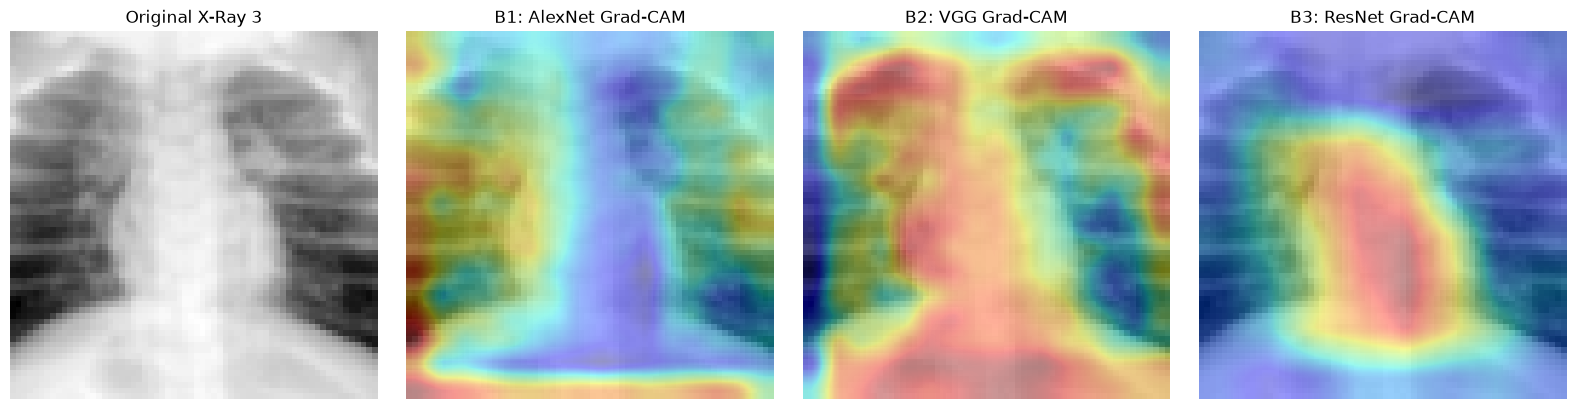

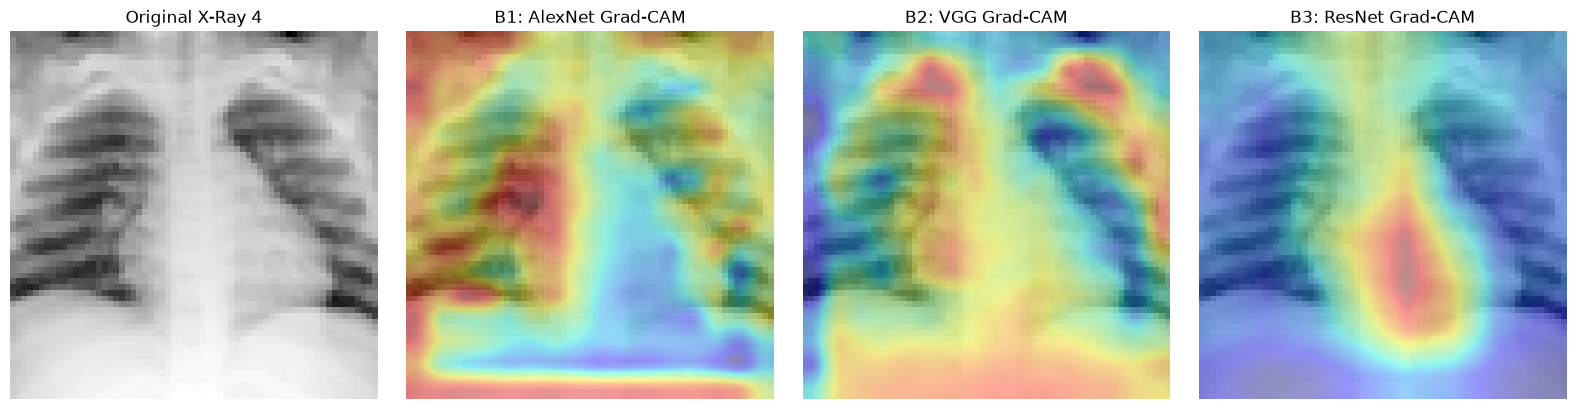

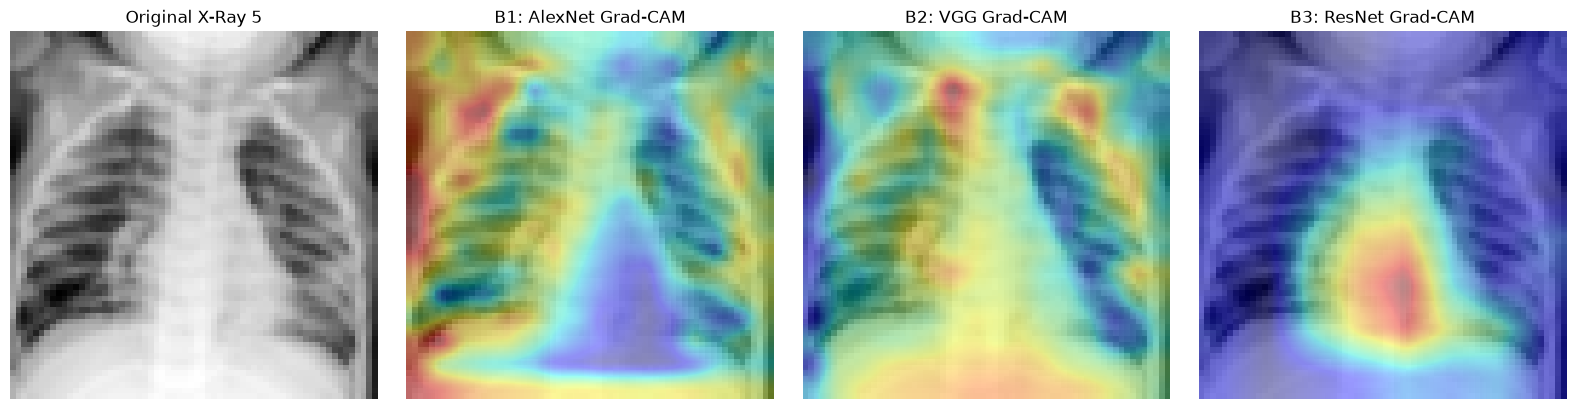

Smooth Grad-CAM images successfully generated and saved to 'images/gradcam/'!
ROC Curve plot saved successfully to images/roc_curve_comparison.png


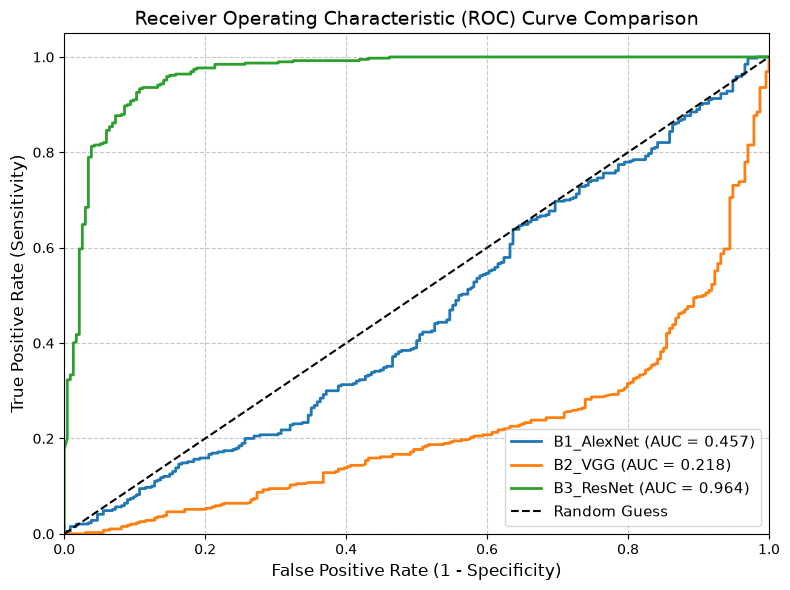

In [33]:
import os
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from captum.attr import LayerGradCam

# --- 1. Helper Function to Find Conv Layers ---
def get_conv_from_block(block):
    """Searches for any Conv2d module inside a custom block."""
    for m in block.modules():
        if isinstance(m, torch.nn.Conv2d):
            return m
    raise ValueError("No Conv2d found in this block")

# --- 2. Modular Grad-CAM Visualization Function ---
def generate_and_save_gradcam(models, sample_images, device, save_dir='images/gradcam'):
    """Generates, overlays, and saves smooth Grad-CAM heatmaps for 5 samples."""
    os.makedirs(save_dir, exist_ok=True)
    
    # Initialize LayerGradCam using appropriate target layers for B1, B2, and B3
    cam_b1 = LayerGradCam(models['B1_AlexNet'], get_conv_from_block(models['B1_AlexNet'].features[4]))
    cam_b2 = LayerGradCam(models['B2_VGG'], get_conv_from_block(models['B2_VGG'].features[6]))
    cam_b3 = LayerGradCam(models['B3_ResNet'], models['B3_ResNet'].layer3)

    cams = [cam_b1, cam_b2, cam_b3]
    model_names = ['B1: AlexNet', 'B2: VGG', 'B3: ResNet']

    print("--- Generating Smooth Grad-CAM Visualizations ---")
    for i in range(len(sample_images)):
        img = sample_images[i:i+1].to(device) # Shape: (1, 1, H, W)
        orig_img_np = img.squeeze(0).cpu().permute(1, 2, 0).numpy().squeeze()
        
        fig, axes = plt.subplots(1, 4, figsize=(16, 4))
        
        # Plot Original X-Ray
        axes[0].imshow(orig_img_np, cmap='gray')
        axes[0].set_title(f"Original X-Ray {i+1}")
        axes[0].axis('off')
        
        # Generate and overlay Grad-CAM for each model
        for idx, (cam, name) in enumerate(zip(cams, model_names), start=1):
            attr = cam.attribute(img, target=None)
            # Smooth upsampling to original dimensions
            attr_up = F.interpolate(attr, size=img.shape[2:], mode='bilinear', align_corners=False)
            
            hm = attr_up.squeeze().detach().cpu().numpy()
            if hm.max() > hm.min():
                hm = (hm - hm.min()) / (hm.max() - hm.min()) # Normalize between 0 and 1
                
            axes[idx].imshow(orig_img_np, cmap='gray')
            axes[idx].imshow(hm, cmap='jet', alpha=0.4, interpolation='bilinear')
            axes[idx].set_title(f"{name} Grad-CAM")
            axes[idx].axis('off')
            
        plt.tight_layout()
        save_path = os.path.join(save_dir, f'sample_{i+1}_gradcam.png')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()

    print(f"Smooth Grad-CAM images successfully generated and saved to '{save_dir}/'!")

# --- 3. Modular ROC Curve Evaluation & Plotting Function ---
def evaluate_and_plot_roc(models, test_loader, device, save_filename='roc_curve_comparison.png'):
    """Computes probabilities, AUC, and plots ROC curves for multiple models."""
    os.makedirs('images', exist_ok=True)
    plt.figure(figsize=(8, 6))
    
    for name, model in models.items():
        model.eval()
        y_true, y_probs = [], []
        with torch.no_grad():
            for inputs, targets in test_loader:
                inputs = inputs.to(device)
                outputs = model(inputs)
                probs = torch.sigmoid(outputs)
                y_true.extend(targets.cpu().numpy())
                y_probs.extend(probs.cpu().numpy())
                
        y_true = np.array(y_true)
        y_probs = np.array(y_probs)
        
        fpr, tpr, _ = roc_curve(y_true, y_probs)
        roc_auc = auc(fpr, tpr)
        
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})', linewidth=2)

    plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Guess')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
    plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
    plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=14)
    plt.legend(loc="lower right", fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    roc_output_path = os.path.join('images', save_filename)
    plt.savefig(roc_output_path, dpi=300, bbox_inches='tight')
    print(f"ROC Curve plot saved successfully to {roc_output_path}")
    plt.show()

# --- 4. Execution Pipeline ---
# Package models dictionary for easy iteration
models_dict = {
    'B1_AlexNet': model_b1,
    'B2_VGG': model_b2,
    'B3_ResNet': model_b3
}

# Select 5 random pneumonia positive samples (target == 1)
pneumonia_indices = torch.where(y_test_t == 1)[0]
sample_indices = pneumonia_indices[torch.randperm(len(pneumonia_indices))[:5]]
sample_images = X_test_t[sample_indices]

# Run Grad-CAM Generation & Overlay
generate_and_save_gradcam(models_dict, sample_images, device)

# Run ROC Curve Analysis & Plotting
evaluate_and_plot_roc(models_dict, test_loader_final, device)

## Error Analysis using Grad CAM

Total False Negatives found: 9
Total False Positives found: 48

--- Generating Grad-CAM for False_Negative (5 samples) ---


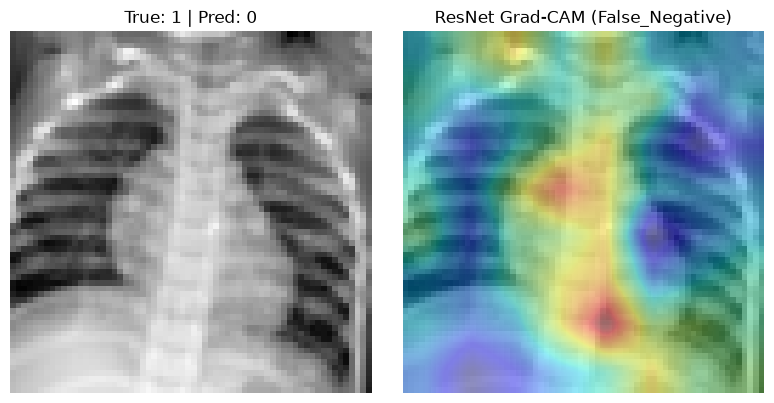

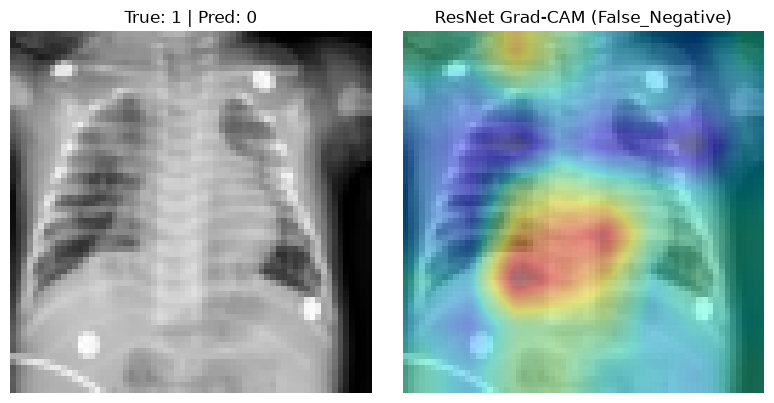

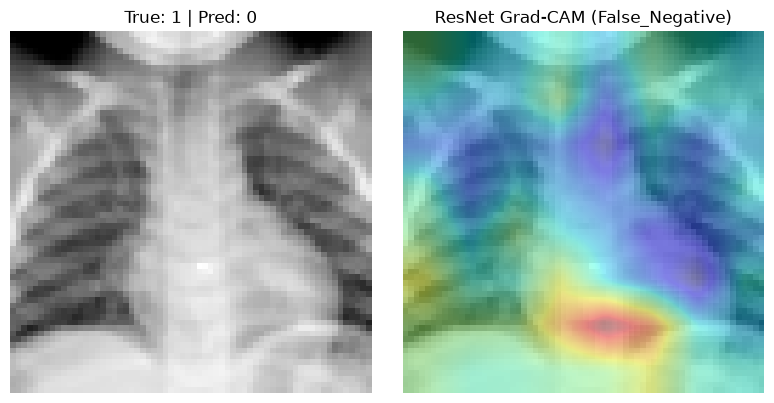

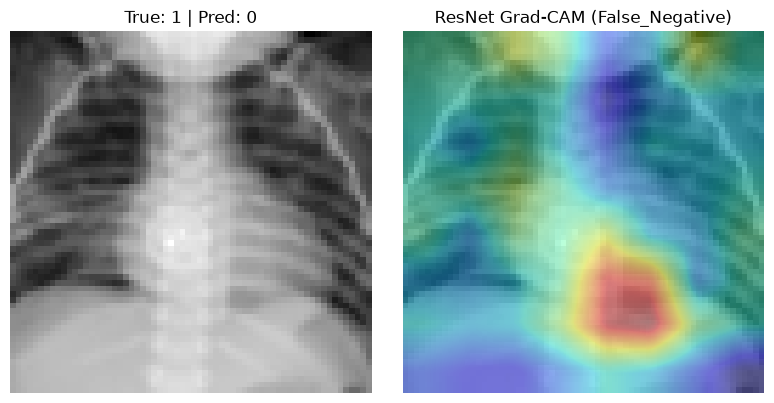

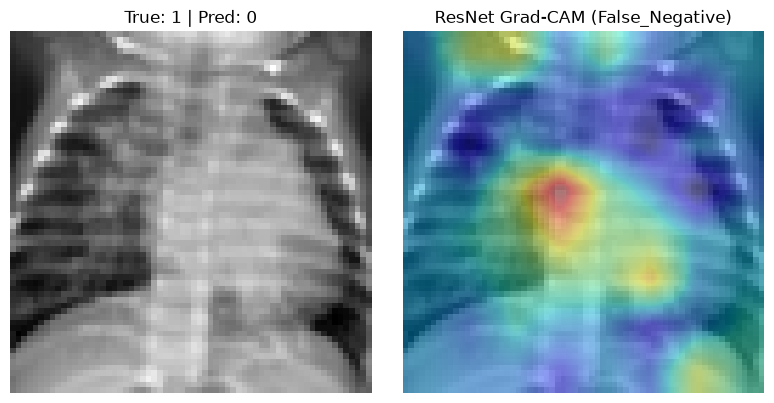


--- Generating Grad-CAM for False_Positive (5 samples) ---


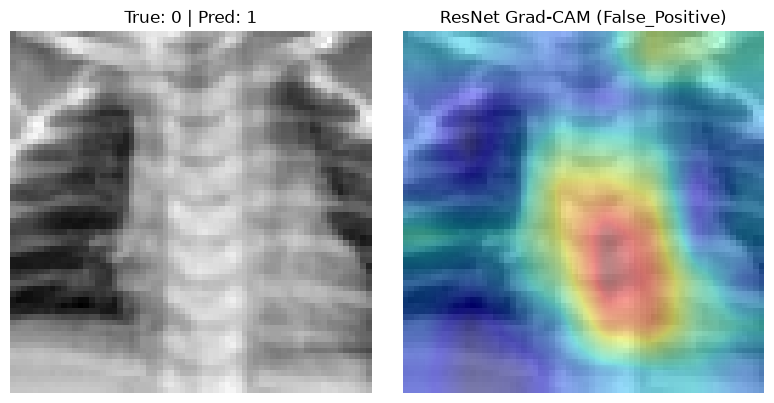

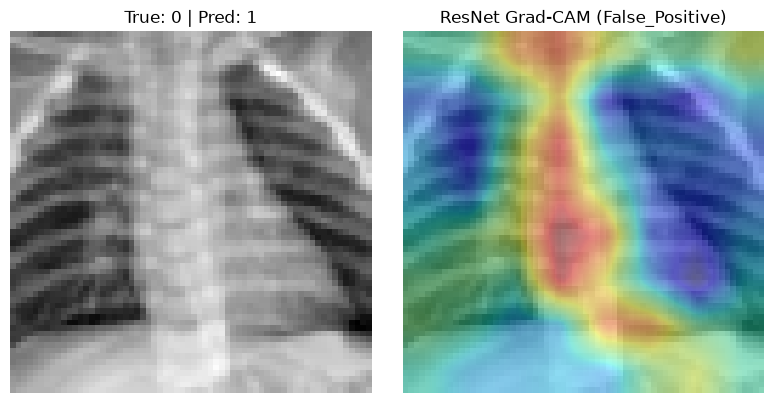

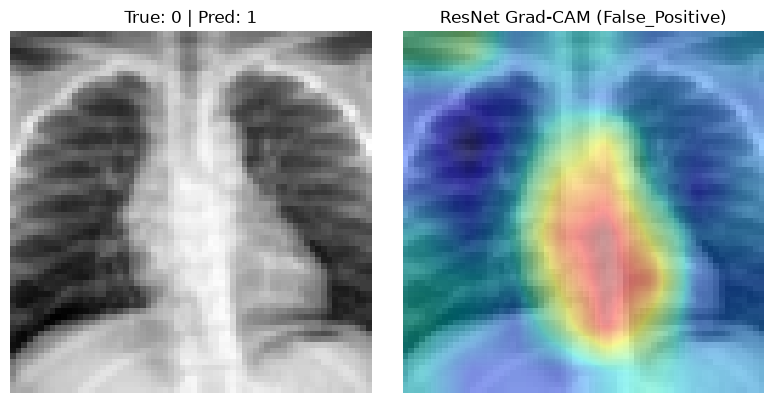

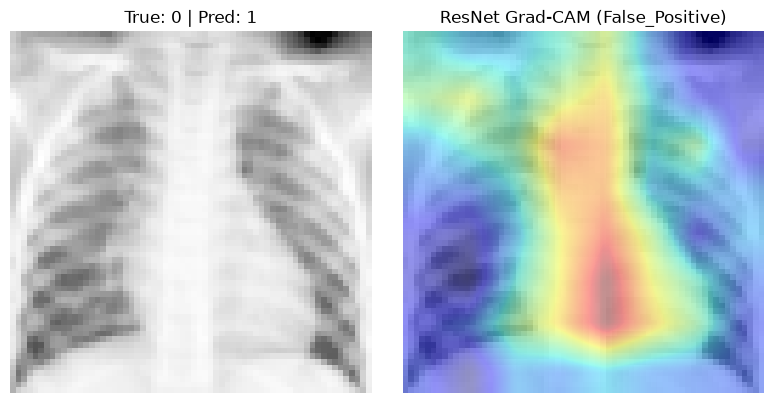

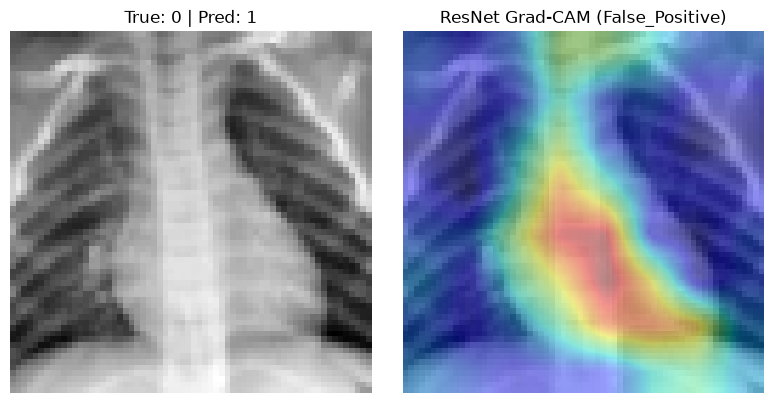

In [32]:
import os
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam

# Ensure output directory exists
os.makedirs('images/error_analysis', exist_ok=True)

# 1. Get predictions for the entire test set using our best model (ResNet - B3)
model_b3.eval()
all_preds, all_targets, all_images = [], [], []

with torch.no_grad():
    for inputs, targets in test_loader_final:
        inputs = inputs.to(device)
        outputs = model_b3(inputs)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())
        all_images.append(inputs.cpu())

all_preds = np.array(all_preds).squeeze()
all_targets = np.array(all_targets).squeeze()
all_images = torch.cat(all_images, dim=0)

# 2. Identify False Negatives and False Positives indices
fn_indices = np.where((all_preds == 0) & (all_targets == 1))[0] # Missed Pneumonia
fp_indices = np.where((all_preds == 1) & (all_targets == 0))[0] # False Alarm (Normal flagged as Pneumonia)

print(f"Total False Negatives found: {len(fn_indices)}")
print(f"Total False Positives found: {len(fp_indices)}")

# 3. Initialize Grad-CAM for ResNet (model_b3)
cam_b3 = LayerGradCam(model_b3, model_b3.layer3)

def generate_error_gradcam(indices, error_type_name):
    if len(indices) == 0:
        print(f"No {error_type_name} samples found to analyze.")
        return
    
    # Pick up to 5 samples
    selected_indices = indices[:5]
    error_images = all_images[selected_indices].to(device)
    
    print(f"\n--- Generating Grad-CAM for {error_type_name} ({len(selected_indices)} samples) ---")
    
    for i, idx in enumerate(selected_indices):
        img = error_images[i:i+1] # Shape: (1, 1, H, W)
        
        # Generate attributions
        attr = cam_b3.attribute(img, target=None)
        
        # Upsample smoothly using bilinear interpolation
        attr_up = F.interpolate(attr, size=img.shape[2:], mode='bilinear', align_corners=False)
        
        orig_img_np = img.squeeze(0).cpu().permute(1, 2, 0).numpy().squeeze()
        hm = attr_up.squeeze().detach().cpu().numpy()
        
        if hm.max() > hm.min():
            hm = (hm - hm.min()) / (hm.max() - hm.min())
            
        # Plotting side-by-side: Original vs Grad-CAM Overlay
        fig, axes = plt.subplots(1, 2, figsize=(8, 4))
        
        # Original Image
        axes[0].imshow(orig_img_np, cmap='gray')
        axes[0].set_title(f"True: {int(all_targets[idx])} | Pred: {int(all_preds[idx])}")
        axes[0].axis('off')
        
        # Grad-CAM Heatmap Overlay
        axes[1].imshow(orig_img_np, cmap='gray')
        axes[1].imshow(hm, cmap='jet', alpha=0.4, interpolation='bilinear')
        axes[1].set_title(f"ResNet Grad-CAM ({error_type_name})")
        axes[1].axis('off')
        
        plt.tight_layout()
        save_path = os.path.join('images/error_analysis', f'{error_type_name}_sample_{i+1}.png')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()

# Run error analysis generation for both categories
generate_error_gradcam(fn_indices, "False_Negative")
generate_error_gradcam(fp_indices, "False_Positive")